In [18]:
import itertools

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# **Section 1**

In [19]:
# loading data

columns = ['exterior', 'size', 'price', 'strap_pad', 'pocket', 'interior']

design = pd.read_csv("design.csv", delimiter=",", header=None, names=columns)
online = pd.read_csv("responses_online.csv", delimiter=",", header=None)
offline = pd.read_csv("responses_offline.csv", delimiter=",", header=None)

design.index.name = 'bag'

print("Design:", design.shape)
print("Online responses:", online.shape)
print("Offline responses:", offline.shape)
display(design.head())
display(online.iloc[:5, :6])

Design: (20, 6)
Online responses: (122, 20)
Offline responses: (122, 20)


,exterior,size,price,strap_pad,pocket,interior
bag,,,,,,
0,1,1,3,1,2,1
1,4,1,2,2,2,2
2,3,1,1,2,1,2
3,2,1,3,2,1,1
4,3,2,3,1,2,3


,0,1,2,3,4,5
0,1,1,1,1,1,1
1,1,4,4,2,3,2
2,2,3,2,2,2,5
3,1,1,1,1,1,1
4,3,4,3,3,4,3


In [20]:
# transform responses to a long format
# (now we have a string as one respondent while we want a string as one review)

def to_long(responses):
    return (responses.rename_axis('respondent').reset_index()
            .melt(id_vars='respondent', var_name='bag', value_name='rate'))

online = to_long(online)
offline = to_long(offline)

print(online.shape)
display(online.head())

# no miss => everything is OK check
print('Missing ratings:', online.rate.isna().sum(), offline.rate.isna().sum())

invalid_online = online[~online.rate.isin([1, 2, 3, 4, 5])]
invalid_offline = offline[~offline.rate.isin([1, 2, 3, 4, 5])]

display(invalid_online)
display(invalid_offline)

(2440, 3)


,respondent,bag,rate
0,0,0,1
1,1,0,1
2,2,0,2
3,3,0,1
4,4,0,3


Missing ratings: 0 0


,respondent,bag,rate


,respondent,bag,rate
1911,81,15,2.5


In [21]:
# dummy coding

price_levels = {1: 120, 2: 140, 3: 160, 4: 180}
cat_features = ['exterior', 'size', 'strap_pad', 'pocket', 'interior']

def encode_design(data):
    result = pd.get_dummies(data, columns=cat_features, drop_first=True, dtype=int)
    result['price'] = result['price'].map(price_levels)
    return result

design_encoded = encode_design(design)
features = design_encoded.columns.tolist()

online = online.merge(design_encoded.reset_index(), on='bag')
offline = offline.merge(design_encoded.reset_index(), on='bag')

display(design_encoded.head())
print('Regression variables:', len(features), '+ intercept')
print('Rank of design matrix:', np.linalg.matrix_rank(sm.add_constant(design_encoded)))

,price,exterior_2,exterior_3,exterior_4,size_2,strap_pad_2,pocket_2,interior_2,interior_3
bag,,,,,,,,,
0,160,0,0,0,0,0,1,0,0
1,140,0,0,1,0,1,1,1,0
2,120,0,1,0,0,1,0,1,0
3,160,1,0,0,0,1,0,0,0
4,160,0,1,0,1,0,1,0,1


Regression variables: 9 + intercept
Rank of design matrix: 10


Now we have cleaned all the data and can run an OLS regression which draws a connection between the average rate for a bag and its charactristic => 20 obs.

In [22]:
# rates (we need to combine both offline and online rates)
rates = online # oh no, we dont need, I have reread the problem. There are a distinct block for offline guys
assert rates.isna().any().any() == False

y_means = rates.groupby('bag').rate.mean().reindex(design_encoded.index)
X_bags = sm.add_constant(design_encoded, has_constant='add')

model_means = sm.OLS(y_means, X_bags).fit()
print(model_means.summary())

                            OLS Regression Results                            
Dep. Variable:                   rate   R-squared:                       0.986
Model:                            OLS   Adj. R-squared:                  0.973
Method:                 Least Squares   F-statistic:                     77.53
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           4.62e-08
Time:                        11:47:45   Log-Likelihood:                 21.900
No. Observations:                  20   AIC:                            -23.80
Df Residuals:                      10   BIC:                            -13.84
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           3.7232      0.198     18.824      

**A basic bag is a small black with an empty bucket and without both a pocket and a strap pad**

The answer depend on a definiton of importance, if we:

1. **See the average coefficient for each feature** => the most important are interior (average coef = .51315), exterior (-.5325), and strap_pad (.51). If we use a range from 120 to 180 to calculate price importance, it gets the first place with $-0.0111*(180-120)=-0.666$. The least important are price (-.01) and size (-.268)
2. **See every feature type on its own**: the most important tips are 1) not to produce colorful bags (-1.06 relatively to the basic bag) and 2) do them with a strap pad (.51), pocket (0.45) and an additional dividers forr a laptop (.6192), 3) control the price seeing that it still has importance (-.666 for a full range, the 2nd place after exterior)

# **Section 2**

There I also used online responses

In [23]:
individual_models = {}

for respondent, data in rates.groupby('respondent'):
    X = sm.add_constant(data[features], has_constant='add')
    individual_models[respondent] = sm.OLS(data.rate, X).fit()

individual_params = pd.DataFrame({i: fit.params for i, fit in individual_models.items()}).T
individual_se = pd.DataFrame({i: fit.bse for i, fit in individual_models.items()}).T
individual_params.index.name = 'respondent'

display(individual_params.head().round(3))

,const,price,exterior_2,exterior_3,exterior_4,size_2,strap_pad_2,pocket_2,interior_2,interior_3
respondent,,,,,,,,,,
0,3.673,-0.018,0.00,-0.397,-0.064,0.6,0.654,0.4,-0.500,0.231
1,3.139,-0.017,0.25,0.065,-0.269,0.1,0.964,0.7,1.333,1.394
2,7.334,-0.030,-0.25,-1.355,-0.355,0.1,0.257,0.1,0.500,1.230
3,2.929,-0.013,-0.25,-0.580,-0.247,0.9,0.192,0.3,-0.000,0.288
4,2.747,-0.005,0.00,0.606,0.440,-0.3,0.464,0.3,0.667,1.060


As we see average respondet coefs == pooled coefs => everything is good

In [24]:
check = pd.DataFrame({
    'Pooled coefficient': model_means.params,
    'Average individual coefficient': individual_params.mean(),
    'SD across respondents': individual_params.std(),
    'Median individual SE': individual_se.median()
})
display(check.round(3))

,Pooled coefficient,Average individual coefficient,SD across respondents,Median individual SE
const,3.723,3.723,1.964,1.059
price,-0.011,-0.011,0.012,0.006
exterior_2,-0.314,-0.314,0.778,0.434
exterior_3,-1.064,-1.064,1.120,0.399
exterior_4,-0.220,-0.220,0.643,0.399
size_2,0.268,0.268,0.553,0.274
strap_pad_2,0.510,0.510,0.548,0.279
pocket_2,0.448,0.448,0.449,0.274
interior_2,0.407,0.407,0.536,0.354
interior_3,0.619,0.619,0.715,0.335


Let's see how the coefs vary across different people

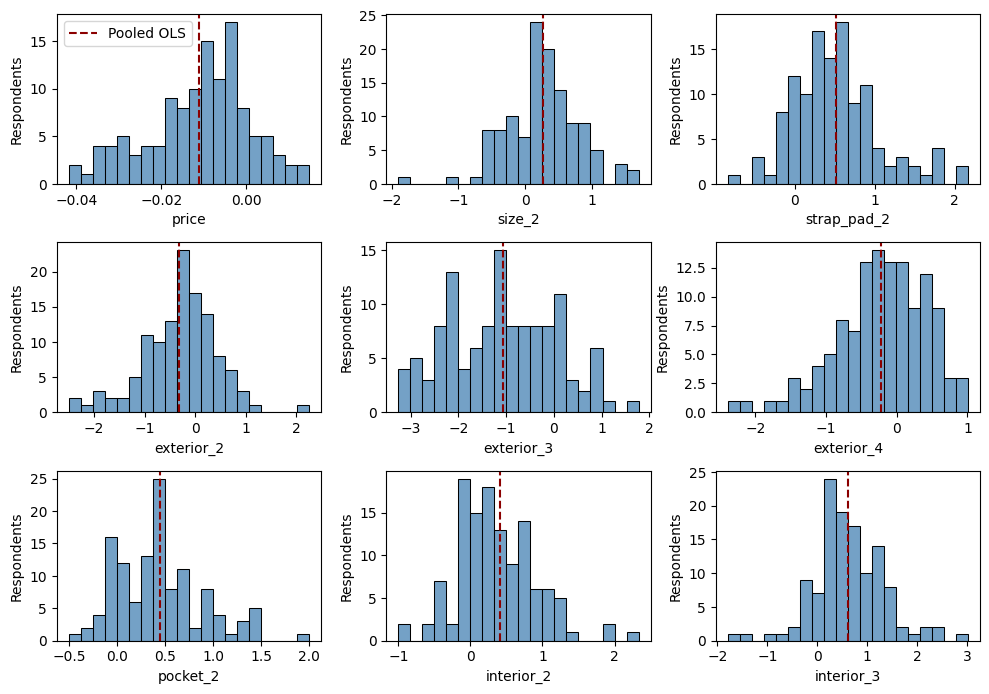

In [25]:
plot_features = ['price', 'size_2', 'strap_pad_2', 'exterior_2', 'exterior_3', 'exterior_4', 'pocket_2', 'interior_2','interior_3']

fig, axes = plt.subplots(3, 3, figsize=(10, 7))
for ax, feature in zip(axes.flat, plot_features):
    sns.histplot(individual_params[feature], bins=20, ax=ax, color='steelblue')
    ax.axvline(model_means.params[feature], color='darkred', linestyle='--', label='Pooled OLS')
    ax.set(xlabel=feature, ylabel='Respondents')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

We see:

1. low dispersion of coefs for interior 3 and 2 (laptop compartment & files divider), strap_pad, pocket and size. Also there is little varience on price (almost all people have negative coefs and many are even in a range of -.02 to -0.01). That can be explained that this features show common preferences: it is better to have a cheaper / bigger or having a divider for files or laptop place bag than a bag not having this feature.

2. The larges varience is in exterior, "features of taste". We see that on average people like any exterior type less than black, but there are a significant group of people who on average with other things beign equal valuate other types better. This is especially seen according to colorful and blue bags, but the distributions wide come across there in every variants in contrast with others having bias

This estimates are noisier than the population one, because 1) of the estimation noise, 2) they reflect not a taste of an average buyer, but the taste of different people which vary significantly especcially in a question of bag beauty standards

# *Section 3*

Since we need to maximize revenue the information about price and preferences is enough. I will assume that a person buys a bag if their estimated rating is 3.5 or higher. After this for each bag I will be able to calculate estimated revenue as $price\cdot buyers=$, where buyers is a number of those whose estimated rating for the bag is 3.5 or higher.

In [26]:
all_bags = pd.DataFrame(
    itertools.product([1, 2, 3, 4], [1, 2], [1, 2, 3, 4], [1, 2], [1, 2], [1, 2, 3]),
    columns=columns
)

all_bags_encoded = encode_design(all_bags)
X_all_bags = sm.add_constant(all_bags_encoded[features], has_constant='add')

print('Configurations:', len(all_bags))
display(all_bags.head())

Configurations: 384


,exterior,size,price,strap_pad,pocket,interior
0,1,1,1,1,1,1
1,1,1,1,1,1,2
2,1,1,1,1,1,3
3,1,1,1,1,2,1
4,1,1,1,1,2,2


In [27]:
# calculate an estimated rating for every bag for every person
# there we use all the configurations

predicted_ratings = individual_params.to_numpy() @ X_all_bags.to_numpy().T
buyers = (predicted_ratings >= 3.5).sum(axis=0)

candidates = all_bags.copy()
candidates['price'] = candidates.price.map(price_levels)
candidates['buyers'] = buyers
candidates['revenue'] = candidates.price * candidates.buyers

# I added sorting to see bags with the largest estimated revenue
candidates = candidates.sort_values(by="revenue", ascending=False).reset_index(drop=True)

display(candidates)

,exterior,size,price,strap_pad,pocket,interior,buyers,revenue
0,1,2,160,2,2,3,84,13440
1,1,2,180,2,2,3,71,12780
2,1,2,140,2,2,3,91,12740
3,4,2,140,2,2,3,83,11620
4,1,2,140,2,2,2,80,11200
...,...,...,...,...,...,...,...,...
379,3,1,180,1,2,1,2,360
380,3,1,180,2,1,1,2,360
381,3,1,160,1,1,2,2,320
382,3,1,160,2,1,1,2,320


We see that a configurtion with a maximum revenue (13440) is a large black bag with a pocket, strap pad and a laptop division priced for 160.

# **Section 4**

To choose two bags with the highest revenue it is essential to remember that:
1) It is more probable that a person would buy only one bag => if we give a choice of 2 we have to check not only the estimated rating being >= 3.5 but what bag is prefered by every person.

Assumptions:
1. A person buys a bag if its estimated rating for him/her is >= 3.5
2. A person buys only one bag of one design
3. A store can not to sell the same bags for different price

In [28]:
prices = all_bags["price"].map(price_levels).to_numpy()
best_revenue = -np.inf

# to ensure that we won't choose the same bags with different price
design_features = ["exterior", "size", "strap_pad", "pocket", "interior"]
bag_designs = all_bags[design_features].to_numpy()

for i, j in itertools.combinations(range(len(all_bags)), 2):
    
    if np.array_equal(bag_designs[i], bag_designs[j]): continue

    pair = [i, j]
    ratings = predicted_ratings[:, pair]

    chosen_bag = ratings.argmax(axis=1)
    will_buy = ratings.max(axis=1) >= 3.5
    pair_buyers = np.bincount(chosen_bag[will_buy], minlength=2)
    revenue = pair_buyers @ prices[pair]

    if revenue > best_revenue:
        best_revenue = revenue
        best_pair = pair
        best_buyer_counts = pair_buyers

print(f"Total revenue: ${best_revenue:,}")
display(all_bags.iloc[best_pair].assign(
    price=prices[best_pair],
    buyers=best_buyer_counts,
    revenue=prices[best_pair] * best_buyer_counts,
))

Total revenue: $14,820


,exterior,size,price,strap_pad,pocket,interior,buyers,revenue
95,1,2,180,2,2,3,63,11340
293,4,1,120,1,2,3,29,3480


We see that the two bag which maximize estimated revenue are:

1. a large black bag with a pocket, strap pad and a laptop division priced for 180 (estimated revenue=11340)
2. A small blue bag without a strap pad but with a pocket and laptop section priced for 120 (estimated revenue=3480)

From 122 respondents $\frac{63+29}{122}=\frac{46}{61}\approx 0.7541$ share will buy a bag

# *Section 5*

We just need to change rates = online to rates = offline, and the analysis will be done for the offline responses.

                            OLS Regression Results                            
Dep. Variable:                   rate   R-squared:                       0.976
Model:                            OLS   Adj. R-squared:                  0.954
Method:                 Least Squares   F-statistic:                     44.38
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           6.91e-07
Time:                        11:47:46   Log-Likelihood:                 20.437
No. Observations:                  20   AIC:                            -20.87
Df Residuals:                      10   BIC:                            -10.92
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           3.3884      0.213     15.923      

,const,price,exterior_2,exterior_3,exterior_4,size_2,strap_pad_2,pocket_2,interior_2,interior_3
respondent,,,,,,,,,,
0,4.557,-0.019,-1.00,-0.448,-0.448,0.2,0.445,0.2,0.167,-0.218
1,0.430,0.015,0.25,0.240,-0.760,-1.1,0.423,-0.1,0.167,0.218
2,10.148,-0.052,-0.50,-0.719,-0.219,-0.5,0.688,0.1,1.167,1.302
3,4.878,-0.022,-0.75,0.468,-0.199,0.1,0.327,-0.1,0.167,-0.176
4,3.682,-0.009,-0.50,0.986,0.319,-0.6,0.127,0.4,0.333,0.764


,Pooled coefficient,Average individual coefficient,SD across respondents,Median individual SE
const,3.388,3.388,2.202,1.141
price,-0.008,-0.008,0.014,0.007
exterior_2,-0.595,-0.595,1.054,0.467
exterior_3,-0.706,-0.706,1.234,0.430
exterior_4,-0.110,-0.110,0.637,0.430
size_2,-0.307,-0.307,0.676,0.295
strap_pad_2,0.253,0.253,0.508,0.300
pocket_2,0.170,0.170,0.378,0.295
interior_2,0.520,0.520,0.513,0.381
interior_3,0.877,0.877,0.793,0.361


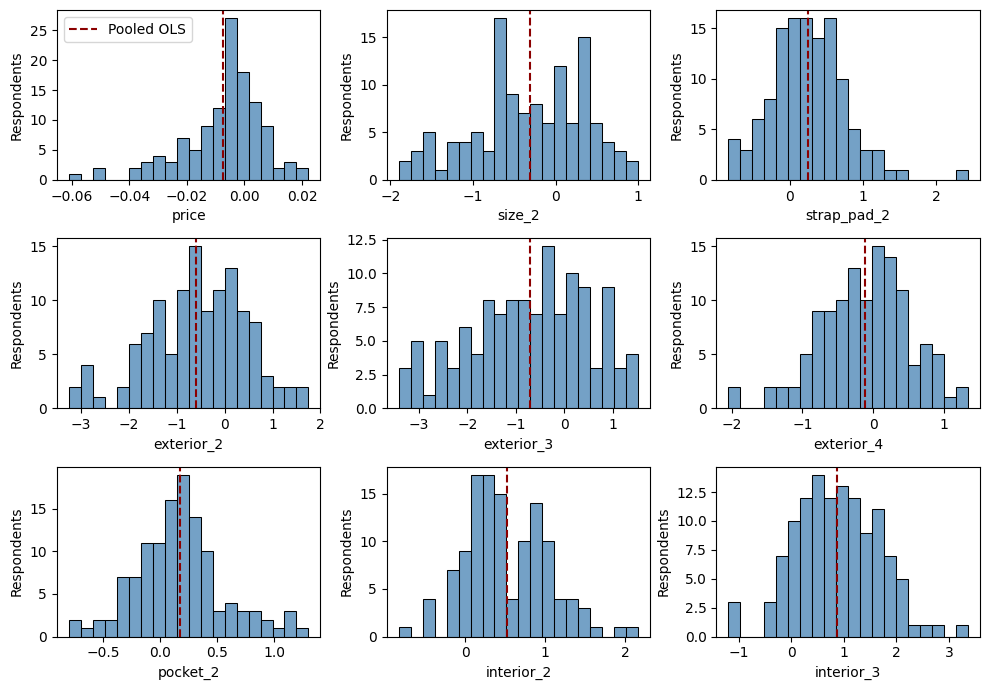

,exterior,size,price,strap_pad,pocket,interior,buyers,revenue
0,1,1,180,2,2,3,58,10440
1,1,1,160,2,2,3,64,10240
2,1,1,140,2,2,3,69,9660
3,1,1,120,2,2,3,75,9000
4,4,1,140,2,2,3,64,8960
...,...,...,...,...,...,...,...,...
379,3,1,160,1,1,1,2,320
380,3,2,160,1,2,1,2,320
381,3,2,140,1,1,1,2,280
382,3,2,160,1,1,1,1,160


In [29]:
# point 1
rates = offline
assert rates.isna().any().any() == False

y_means_off = rates.groupby('bag').rate.mean().reindex(design_encoded.index)

model_means_off = sm.OLS(y_means_off, X_bags).fit()
print(model_means_off.summary())

# point 2
individual_models_off = {}

for respondent, data in rates.groupby('respondent'):
    X = sm.add_constant(data[features], has_constant='add')
    individual_models_off[respondent] = sm.OLS(data.rate, X).fit()

individual_params_off = pd.DataFrame({i: fit.params for i, fit in individual_models_off.items()}).T
individual_se_off = pd.DataFrame({i: fit.bse for i, fit in individual_models_off.items()}).T
individual_params_off.index.name = 'respondent'

display(individual_params_off.head().round(3))

check_off = pd.DataFrame({
    'Pooled coefficient': model_means_off.params,
    'Average individual coefficient': individual_params_off.mean(),
    'SD across respondents': individual_params_off.std(),
    'Median individual SE': individual_se_off.median()
})
display(check_off.round(3))

plot_features = ['price', 'size_2', 'strap_pad_2', 'exterior_2', 'exterior_3', 'exterior_4', 'pocket_2', 'interior_2','interior_3']

fig, axes = plt.subplots(3, 3, figsize=(10, 7))
for ax, feature in zip(axes.flat, plot_features):
    sns.histplot(individual_params_off[feature], bins=20, ax=ax, color='steelblue')
    ax.axvline(model_means_off.params[feature], color='darkred', linestyle='--', label='Pooled OLS')
    ax.set(xlabel=feature, ylabel='Respondents')
axes[0, 0].legend()
plt.tight_layout()
plt.show()


# point 3

predicted_ratings_off = individual_params_off.to_numpy() @ X_all_bags.to_numpy().T
buyers_off = (predicted_ratings_off >= 3.5).sum(axis=0)

candidates_off = all_bags.copy()
candidates_off['price'] = candidates_off.price.map(price_levels)
candidates_off['buyers'] = buyers_off
candidates_off['revenue'] = candidates_off.price * candidates_off.buyers

# I added sorting to see bags with the largest estimated revenue
candidates_off = candidates_off.sort_values(by="revenue", ascending=False).reset_index(drop=True)

display(candidates_off)

**Section 3 (offline) answer**: a small black bag with a strap pad, pocket and lapton section priced for 180

The copied analysis for Section 1-4 is available above, now I will do comparison code.

In [30]:
paired = online[['respondent', 'bag', 'rate']].merge(
    offline[['respondent', 'bag', 'rate']],
    on=['respondent', 'bag'], suffixes=('_online', '_offline')
)
paired['difference'] = paired.rate_offline - paired.rate_online

print(f'Online mean:  {paired.rate_online.mean():.3f}')
print(f'Offline mean: {paired.rate_offline.mean():.3f}')
print(f'Same rating in both conditions: {(paired.difference == 0).mean():.1%}')

display(paired.head())

Online mean:  2.609
Offline mean: 2.473
Same rating in both conditions: 40.2%


,respondent,bag,rate_online,rate_offline,difference
0,0,0,1,1.0,0.0
1,1,0,1,3.0,2.0
2,2,0,2,2.0,0.0
3,3,0,1,1.0,0.0
4,4,0,3,3.0,0.0


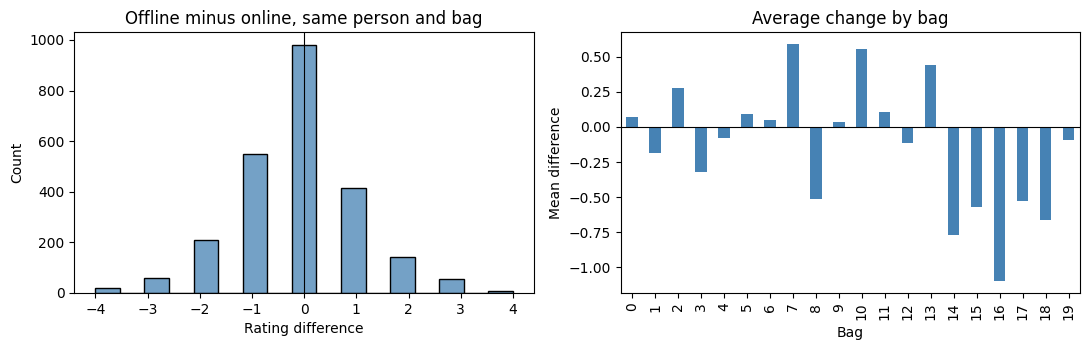

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

sns.histplot(paired.difference, bins=17, ax=axes[0], color='steelblue')
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set(title='Offline minus online, same person and bag', xlabel='Rating difference')

paired.groupby('bag').difference.mean().plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(title='Average change by bag', xlabel='Bag', ylabel='Mean difference')

plt.tight_layout()
plt.show()

We see that 40.2% ratings made by a person for a bag have equal score for offline and online ratings. Moreover, the distribution plot for the rating difference looks close to a normal distrimution with zero mean. 

However, there is a group of bags with negative average change (bags 14-18). I find this really curious and therefore run an additional OLS regression of the difference by the bags configurations.

I clustered the SE on a respondent level, because one respondent rated many bags (20) and therefore her/his ratings share a part of same information. Not forget to use a difference regression type with z-tests.

In [32]:
difference_data = paired.merge(
    design_encoded.reset_index(),
    on='bag',
    validate='many_to_one'
)

X_difference = sm.add_constant(
    difference_data[features], has_constant='add'
)

model_difference = sm.OLS(
    difference_data['difference'],
    X_difference
).fit(
    cov_type='cluster',
    cov_kwds={'groups': difference_data['respondent']}
)

print(model_difference.summary())

                            OLS Regression Results                            
Dep. Variable:             difference   R-squared:                       0.118
Model:                            OLS   Adj. R-squared:                  0.115
Method:                 Least Squares   F-statistic:                     22.15
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           8.61e-22
Time:                        11:47:47   Log-Likelihood:                -3850.2
No. Observations:                2440   AIC:                             7720.
Df Residuals:                    2430   BIC:                             7778.
Df Model:                           9                                         
Covariance Type:              cluster                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.3348      0.203     -1.653      

Check that the coefficients of the difference regression matches with a difference between online and offline pooled regressions.

In [33]:
display(pd.DataFrame({
    'Online': model_means.params,
    'Offline': model_means_off.params,
    'Offline minus online coefficients':
        model_means_off.params - model_means.params,
    'Difference regression': model_difference.params,
}).round(4))

,Online,Offline,Offline minus online coefficients,Difference regression
const,3.7232,3.3884,-0.3348,-0.3348
price,-0.0111,-0.0075,0.0036,0.0036
exterior_2,-0.3135,-0.5953,-0.2818,-0.2818
exterior_3,-1.0642,-0.7057,0.3585,0.3585
exterior_4,-0.2199,-0.1101,0.1098,0.1098
size_2,0.2680,-0.3070,-0.5750,-0.5750
strap_pad_2,0.5100,0.2532,-0.2569,-0.2569
pocket_2,0.4484,0.1701,-0.2783,-0.2783
interior_2,0.4071,0.5198,0.1127,0.1127
interior_3,0.6192,0.8773,0.2582,0.2582


The coefficents are mostly statistically significant. However, the difference regression got low $R^2=0.12$, and therefore explains little of the variation. Anyway, the largest effect on this little part is gotten by size (large bags got on 0.575 less offline than online relatively to small ones) and colorful exterion (+0.3585 relatively to a black bag if a bag is seen offline, not online).